# **PROYEK STATISTICAL MACHINE LEARNING**
## **Klasifikasi Kejadian Hujan Satu Jam ke Depan di Pekanbaru: SVM dan ANN**

**Tujuan:** mendeteksi kejadian hujan pada satu jam berikutnya dengan prioritas mengurangi *False Negative* (FN), yaitu hujan yang diprediksi tidak hujan.

### Rancangan analisis
- Data: dataset [Open-Meteo](https://open-meteo.com/en/docs/historical-weather-api) yang sudah melalui [feature engineering](https://colab.research.google.com/drive/1F52dXUlKlTxzGXOO5jK2-WhErB3yOwCV?usp=sharing).
- Target: `target_hujan_next_1h` (0 = tidak hujan, 1 = hujan).
- Pembagian: **80%** data paling awal untuk development dan **20%** data terbaru untuk test.
- Validasi: **5-fold** expanding-window menggunakan `TimeSeriesSplit`.
- Baseline: `DummyClassifier(strategy="most_frequent")`.
- Model: **SVM** kernel RBF dan **ANN** menggunakan TensorFlow/Keras.
- Imbalance: tidak menggunakan SMOTE pada eksperimen awal; tapi akan membandingkan model **tanpa pembobotan** dan **dengan pembobotan kelas**.
- Threshold: dipilih dari **prediksi out-of-fold** pada development data dengan memaksimalkan F2-score kelas hujan.
- Metrik utama: **Recall** kelas hujan, **F2-score** kelas hujan, **Balanced Accuracy**, dan **Confusion Matrix**.

## **1. Import library, konfigurasi, dan font**

In [1]:
import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    fbeta_score, roc_auc_score, average_precision_score
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)

import urllib.request
import matplotlib.font_manager as fm

# Unduh file Poppins Regular dan Bold dari direct link raw GitHub Google Fonts
fonts = {
    "Poppins-Regular.ttf": "https://github.com/google/fonts/raw/main/ofl/poppins/Poppins-Regular.ttf",
    "Poppins-Bold.ttf": "https://github.com/google/fonts/raw/main/ofl/poppins/Poppins-Bold.ttf"
}

for filename, url in fonts.items():
    try:
        print(f"Downloading {filename}...")
        urllib.request.urlretrieve(url, filename)
        fm.fontManager.addfont(filename)
        print(f"Success: {filename} added.")
    except Exception as e:
        print(f"Failed to download/install {filename}: {e}")

import zipfile
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from matplotlib.colors import ListedColormap

print("\nSemua library berhasil diimpor.")

TensorFlow: 2.21.0
Success: Poppins-Regular.ttf added.
Success: Poppins-Bold.ttf added.

Semua library berhasil diimpor.


## **2. Upload CSV dataset**

In [2]:
file_path = '/content/dataset_klasifikasi_hujan_pekanbaru.csv'
print("File yang digunakan:", file_path)

df = pd.read_csv(file_path, sep=None, engine='python') # sep=None dan engine='python' agar pandas mendeteksi delimiter secara otomatis (misalnya , atau ;)
print("Ukuran dataset:", df.shape)
display(df.head())

File yang digunakan: /content/dataset_klasifikasi_hujan_pekanbaru.csv
Ukuran dataset: (6573, 21)


,time,temperature_2m,relative_humidity_2m,dew_point_2m,pressure_msl,cloud_cover,cloud_cover_low,wind_speed_10m,wind_gusts_10m,wind_direction_sin,...,shortwave_radiation,vapour_pressure_deficit,boundary_layer_height,soil_moisture_0_to_7cm,rain_prev_1h,rain_prev_2h,rain_prev_3h,hour_sin,hour_cos,target_hujan_next_1h
0,18/01/2026 02:00,24.2,92,22.8,1007.4,100,9,3.4,7.2,-0.9945218953682734,...,0.0,0.25,45.0,0.199,0.0,0.0,0.1,0.49999999999999994,0.8660254037844387,0
1,18/01/2026 03:00,24.3,92,23.0,1007.1,100,1,4.5,8.6,-0.08715574274765832,...,0.0,0.23,65.0,0.199,0.0,0.0,0.0,0.7071067811865475,0.7071067811865476,1
2,18/01/2026 04:00,23.4,94,22.4,1007.4,100,17,8.4,16.6,0.6018150231520483,...,0.0,0.16,135.0,0.200,0.1,0.0,0.0,0.8660254037844386,0.5000000000000001,1
3,18/01/2026 05:00,22.9,93,21.8,1007.6,99,85,6.0,15.8,0.42261826174069944,...,0.0,0.19,190.0,0.203,0.3,0.1,0.0,0.9659258262890683,0.25881904510252074,1
4,18/01/2026 06:00,22.8,95,22.0,1007.8,100,45,7.5,14.0,0.6018150231520483,...,0.0,0.14,205.0,0.205,0.2,0.3,0.1,1.0,"6,12E-02",0


## **3. EDA**

In [3]:
# Memastikan kolom waktu dan target tersedia.
TARGET = "target_hujan_next_1h"
TIME_COL = "time"

# Membaca tanggal sesuai format aktual dataset.
df[TIME_COL] = pd.to_datetime(
    df[TIME_COL],
    format="%d/%m/%Y %H:%M",
    errors="raise"
)

# Mengurutkan data secara kronologis.
df = (
    df.sort_values(TIME_COL)
      .reset_index(drop=True)
)

print("Ukuran dataset:", df.shape)

print("\nRentang waktu:")
print("Awal :", df[TIME_COL].min())
print("Akhir:", df[TIME_COL].max())

print("\nTipe data:")
display(df.dtypes.to_frame("dtype"))

print("\nMissing value:")
display(df.isna().sum().to_frame("missing"))

print("\nJumlah baris duplikat:", df.duplicated().sum())
print("Jumlah timestamp duplikat:", df[TIME_COL].duplicated().sum())

print("\nDistribusi target:")
display(
    df[TARGET]
    .value_counts()
    .sort_index()
    .rename(index={0: "Tidak hujan (0)", 1: "Hujan (1)"})
    .to_frame("jumlah")
    .assign(
        persentase=lambda x: (
            x["jumlah"] / x["jumlah"].sum() * 100
        ).round(2).astype(str) + "%"
    )
)

Ukuran dataset: (6573, 21)

Rentang waktu:
Awal : 2026-01-18 02:00:00
Akhir: 2026-10-18 22:00:00

Tipe data:


,dtype
time,datetime64[ns]
temperature_2m,float64
relative_humidity_2m,int64
dew_point_2m,float64
pressure_msl,float64
cloud_cover,int64
cloud_cover_low,int64
wind_speed_10m,float64
wind_gusts_10m,float64
wind_direction_sin,object



Missing value:


,missing
time,0
temperature_2m,0
relative_humidity_2m,0
dew_point_2m,0
pressure_msl,0
cloud_cover,0
cloud_cover_low,0
wind_speed_10m,0
wind_gusts_10m,0
wind_direction_sin,0



Jumlah baris duplikat: 0
Jumlah timestamp duplikat: 0

Distribusi target:


,jumlah,persentase
target_hujan_next_1h,,
Tidak hujan (0),4490,68.31%
Hujan (1),2083,31.69%


## **4. Menentukan fitur (X) dan target (y)**

In [4]:
# Semua kolom selain waktu dan target digunakan sebagai prediktor.
FEATURES = [
    c for c in df.columns
    if c not in [TIME_COL, TARGET]
]

# Memisahkan prediktor dan target.
X = df[FEATURES].copy()
y = df[TARGET].copy()

# Mengubah prediktor menjadi numerik.
for col in FEATURES:
    if X[col].dtype == "object":
        X[col] = X[col].astype(str).str.replace(",", ".", regex=False)

    X[col] = pd.to_numeric(X[col], errors="coerce")

# Memeriksa missing value setelah konversi.
print("Missing value setelah konversi:")
display(X.isna().sum().to_frame("missing"))

# Mempertahankan baris yang seluruh prediktornya valid.
valid_rows = X.notna().all(axis=1) & y.notna()

X = X.loc[valid_rows].reset_index(drop=True)
y = y.loc[valid_rows].astype(int).reset_index(drop=True)
time_data = df.loc[valid_rows, TIME_COL].reset_index(drop=True)

if set(y.unique()) != {0, 1}:
    raise ValueError("Target harus memiliki kelas 0 dan 1.")

print("\nJumlah observasi:", len(X))
print("Jumlah prediktor:", X.shape[1])
print("Prediktor:", FEATURES)

print("\nDistribusi target:")
display(
    y.value_counts()
    .sort_index()
    .rename(index={
        0: "Tidak hujan (0)",
        1: "Hujan (1)"
    })
    .to_frame("jumlah")
    .assign(
        persentase=lambda x: (
            x["jumlah"] / x["jumlah"].sum() * 100
        ).round(2).astype(str) + "%"
    )
)

class_counts = y.value_counts().sort_index()
majority = class_counts.max()
minority = class_counts.min()
print(f"Imbalance ratio (mayoritas/minoritas): {majority/minority:.2f}:1")

Missing value setelah konversi:


,missing
temperature_2m,0
relative_humidity_2m,0
dew_point_2m,0
pressure_msl,0
cloud_cover,0
cloud_cover_low,0
wind_speed_10m,0
wind_gusts_10m,0
wind_direction_sin,0
wind_direction_cos,0



Jumlah observasi: 6573
Jumlah prediktor: 19
Prediktor: ['temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'pressure_msl', 'cloud_cover', 'cloud_cover_low', 'wind_speed_10m', 'wind_gusts_10m', 'wind_direction_sin', 'wind_direction_cos', 'shortwave_radiation', 'vapour_pressure_deficit', 'boundary_layer_height', 'soil_moisture_0_to_7cm', 'rain_prev_1h', 'rain_prev_2h', 'rain_prev_3h', 'hour_sin', 'hour_cos']

Distribusi target:


,jumlah,persentase
target_hujan_next_1h,,
Tidak hujan (0),4490,68.31%
Hujan (1),2083,31.69%


Imbalance ratio (mayoritas/minoritas): 2.16:1


## **5. Time-based split 80:20**

In [6]:
# Time-based split 80:20
split_idx = int(len(X) * 0.80)

X_dev = X.iloc[:split_idx].copy()
X_test = X.iloc[split_idx:].copy()

y_dev = y.iloc[:split_idx].copy()
y_test = y.iloc[split_idx:].copy()

time_dev = time_data.iloc[:split_idx]
time_test = time_data.iloc[split_idx:]

print("DEVELOPMENT")
print("Jumlah:", len(X_dev))
print("Periode:", time_dev.min(), "s.d.", time_dev.max())
print("Proporsi hujan:", round(y_dev.mean() * 100, 2), "%")

print("\nTEST")
print("Jumlah:", len(X_test))
print("Periode:", time_test.min(), "s.d.", time_test.max())
print("Proporsi hujan:", round(y_test.mean() * 100, 2), "%")

# Validasi 5-fold expanding window
tscv = TimeSeriesSplit(n_splits=5)

print("\nSkema validasi: TimeSeriesSplit dengan 5 folds")

DEVELOPMENT
Jumlah: 5258
Periode: 2026-01-18 02:00:00 s.d. 2026-08-25 03:00:00
Proporsi hujan: 30.66 %

TEST
Jumlah: 1315
Periode: 2026-08-25 04:00:00 s.d. 2026-10-18 22:00:00
Proporsi hujan: 35.82 %

Skema validasi: TimeSeriesSplit dengan 5 folds


## **6. Fungsi metrik evaluasi**

In [7]:
# Kelas positif = hujan (1).
# F2-score memberi bobot lebih besar pada Recall daripada Precision.
def calculate_metrics(y_true, y_pred, y_score=None):
    result = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision_hujan": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall_hujan": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "F1_hujan": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "F2_hujan": fbeta_score(y_true, y_pred, beta=2, pos_label=1, zero_division=0)
    }
    if y_score is not None:
        result["ROC_AUC"] = roc_auc_score(y_true, y_score)
        result["Average_Precision"] = average_precision_score(y_true, y_score)
    return result

def show_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Purples",
                xticklabels=["Prediksi 0", "Prediksi 1"],
                yticklabels=["Aktual 0", "Aktual 1"])
    plt.title(title)
    plt.xlabel("Prediksi")
    plt.ylabel("Aktual")
    plt.tight_layout()
    plt.show()
    tn, fp, fn, tp = cm.ravel()
    print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
    return cm

## **7. Baseline dengan DummyClassifier**

Baseline - fold 1 selesai.
Baseline - fold 2 selesai.
Baseline - fold 3 selesai.
Baseline - fold 4 selesai.
Baseline - fold 5 selesai.

Baseline - Cross Validation


,Nilai
Accuracy,0.683562
Balanced Accuracy,0.500000
Precision_hujan,0.000000
Recall_hujan,0.000000
F1_hujan,0.000000
F2_hujan,0.000000



Baseline - Test


,Nilai
Accuracy,0.641825
Balanced Accuracy,0.500000
Precision_hujan,0.000000
Recall_hujan,0.000000
F1_hujan,0.000000
F2_hujan,0.000000


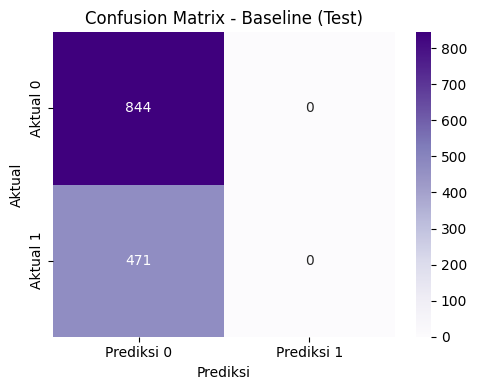

TN=844, FP=0, FN=471, TP=0


array([[844,   0],
       [471,   0]])

In [8]:
# Baseline menggunakan strategi kelas mayoritas.
baseline_oof_true, baseline_oof_pred = [], []

for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_dev), start=1):

    dummy = DummyClassifier(strategy="most_frequent")
    dummy.fit(X_dev.iloc[tr_idx], y_dev.iloc[tr_idx])

    pred = dummy.predict(X_dev.iloc[val_idx])

    baseline_oof_true.extend(y_dev.iloc[val_idx].tolist())
    baseline_oof_pred.extend(pred.tolist())

    print(f"Baseline - fold {fold} selesai.")

# Evaluasi baseline pada validation.
baseline_cv_metrics = calculate_metrics(
    baseline_oof_true,
    baseline_oof_pred
)

print("\nBaseline - Cross Validation")
display(pd.DataFrame([baseline_cv_metrics]).T.rename(columns={0:"Nilai"}))

# Fit baseline menggunakan seluruh development data.
dummy_final = DummyClassifier(strategy="most_frequent")
dummy_final.fit(X_dev, y_dev)

# Evaluasi pada test data.
baseline_test_pred = dummy_final.predict(X_test)
baseline_test_metrics = calculate_metrics(y_test, baseline_test_pred)

print("\nBaseline - Test")
display(pd.DataFrame([baseline_test_metrics]).T.rename(columns={0:"Nilai"}))

show_confusion_matrix(
    y_test,
    baseline_test_pred,
    "Confusion Matrix - Baseline (Test)"
)

## **8. Fungsi threshold tuning**

In [9]:
# Threshold dipilih hanya dari prediksi out-of-fold development data.
# Kriteria utama adalah F2-score kelas hujan; jika nilainya sama, dipilih threshold dengan Recall lebih tinggi.
def choose_threshold(y_true, scores, n_grid=250):
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)

    # Grid threshold berdasarkan rentang skor validasi.
    low, high = np.nanmin(scores), np.nanmax(scores)
    thresholds = np.linspace(low, high, n_grid)

    rows = []
    for threshold in thresholds:
        pred = (scores >= threshold).astype(int)
        rows.append({
            "threshold": threshold,
            "F2_hujan": fbeta_score(y_true, pred, beta=2, pos_label=1, zero_division=0),
            "Recall_hujan": recall_score(y_true, pred, pos_label=1, zero_division=0),
            "Precision_hujan": precision_score(y_true, pred, pos_label=1, zero_division=0),
            "Balanced_Accuracy": balanced_accuracy_score(y_true, pred)
        })

    table = pd.DataFrame(rows)
    best = table.sort_values(
        ["F2_hujan", "Recall_hujan", "Precision_hujan"],
        ascending=[False, False, False]
    ).iloc[0]
    return float(best["threshold"]), table.sort_values("threshold").reset_index(drop=True)

def plot_threshold_curve(table, title):
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(table["threshold"], table["F2_hujan"], label="F2 hujan")
    ax.plot(table["threshold"], table["Recall_hujan"], label="Recall hujan")
    ax.plot(table["threshold"], table["Precision_hujan"], label="Precision hujan")
    ax.set_title(title)
    ax.set_xlabel("Threshold")
    ax.set_ylabel("Skor")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

## **9. SVM: 5-fold expanding-window validation & kernel RBF**

SVM_unweighted - fold 1 selesai.
SVM_unweighted - fold 2 selesai.
SVM_unweighted - fold 3 selesai.
SVM_unweighted - fold 4 selesai.
SVM_unweighted - fold 5 selesai.

SVM_unweighted | threshold keputusan = -1.1016


,Nilai
Accuracy,0.573288
Balanced Accuracy,0.666951
Precision_hujan,0.420533
Recall_hujan,0.922078
F1_hujan,0.577627
F2_hujan,0.744495
ROC_AUC,0.816203
Average_Precision,0.697130


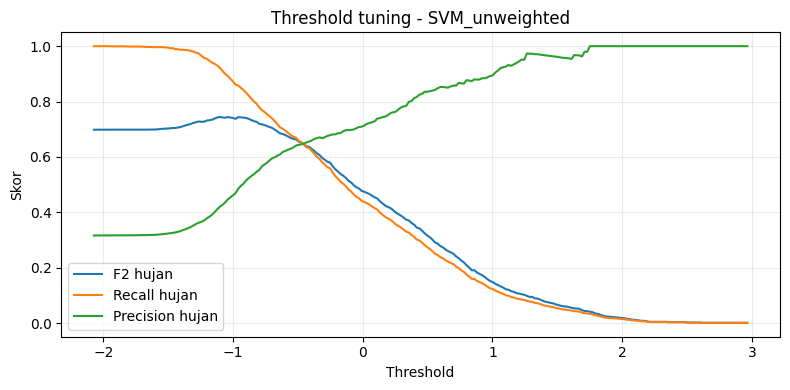

SVM_balanced - fold 1 selesai.
SVM_balanced - fold 2 selesai.
SVM_balanced - fold 3 selesai.
SVM_balanced - fold 4 selesai.
SVM_balanced - fold 5 selesai.

SVM_balanced | threshold keputusan = -0.5816


,Nilai
Accuracy,0.667123
Balanced Accuracy,0.726288
Precision_hujan,0.485782
Recall_hujan,0.887446
F1_hujan,0.627871
F2_hujan,0.761516
ROC_AUC,0.824374
Average_Precision,0.689006


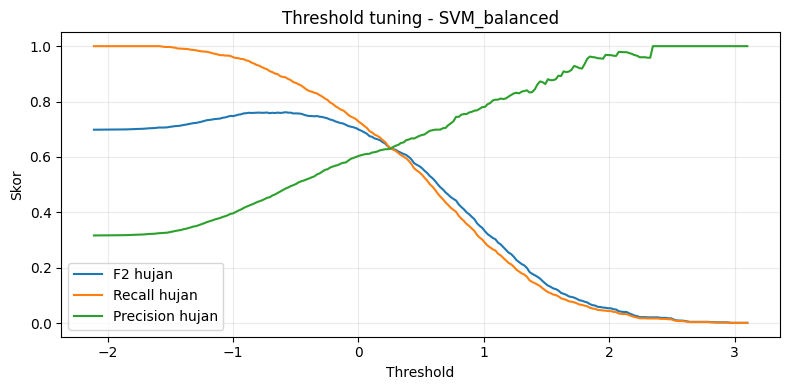

In [10]:
svm_results = {}

#2 perlakuan dibandingkan: tanpa dan dengan class_weight="balanced"
for setting_name, class_weight in [
    ("SVM_unweighted", None),
    ("SVM_balanced", "balanced")
]:
    oof_true, oof_scores = [], []

    for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_dev), start=1):
        svm_pipe = Pipeline([
            ("scaler", StandardScaler()), #StandardScaler di-fit hanya di training fold.
            ("svm", SVC(kernel="rbf", C=1.0, gamma="scale", #SVM kernel RBF
                        class_weight=class_weight))
        ])

        svm_pipe.fit(X_dev.iloc[tr_idx], y_dev.iloc[tr_idx])
        scores = svm_pipe.decision_function(X_dev.iloc[val_idx])
        #threshold diterapkan pada `decision_function`, bukan probabilitas.
        #Maka, nilai threshold SVM tidak ditafsirkan sebagai probabilitas.

        oof_true.extend(y_dev.iloc[val_idx].tolist())
        oof_scores.extend(scores.tolist())

        print(f"{setting_name} - fold {fold} selesai.")

    threshold, threshold_table = choose_threshold(oof_true, oof_scores)
    oof_pred = (np.asarray(oof_scores) >= threshold).astype(int)
    metrics = calculate_metrics(oof_true, oof_pred, np.asarray(oof_scores))

    svm_results[setting_name] = {
        "class_weight": class_weight,
        "threshold": threshold,
        "oof_true": np.asarray(oof_true),
        "oof_scores": np.asarray(oof_scores),
        "threshold_table": threshold_table,
        "cv_metrics": metrics
    }

    print(f"\n{setting_name} | threshold keputusan = {threshold:.4f}")
    display(pd.DataFrame([metrics]).T.rename(columns={0:"Nilai"}))
    plot_threshold_curve(threshold_table, f"Threshold tuning - {setting_name}")

## **10. Memilih konfigurasi SVM berdasarkan validation**

In [11]:
#Pemilihan dilakukan menggunakan F2-score. Recall sebagai pemecah seri.
best_svm_name = max(
    svm_results,
    key=lambda k: (
        svm_results[k]["cv_metrics"]["F2_hujan"],
        svm_results[k]["cv_metrics"]["Recall_hujan"]
    )
)
best_svm = svm_results[best_svm_name]
print("Konfigurasi SVM terpilih:", best_svm_name)
print("Threshold terpilih:", best_svm["threshold"])
display(pd.DataFrame({k:v["cv_metrics"] for k,v in svm_results.items()}).T)

Konfigurasi SVM terpilih: SVM_balanced
Threshold terpilih: -0.5816361110207529


,Accuracy,Balanced Accuracy,Precision_hujan,Recall_hujan,F1_hujan,F2_hujan,ROC_AUC,Average_Precision
SVM_unweighted,0.573288,0.666951,0.420533,0.922078,0.577627,0.744495,0.816203,0.697130
SVM_balanced,0.667123,0.726288,0.485782,0.887446,0.627871,0.761516,0.824374,0.689006


## **11. Fit SVM terpilih dan evaluasi test 1x**

SVM terpilih: SVM_balanced
Threshold keputusan: -0.5816


,Nilai
Accuracy,0.751331
Balanced Accuracy,0.787044
Precision_hujan,0.600559
Recall_hujan,0.912951
F1_hujan,0.724516
F2_hujan,0.826923
ROC_AUC,0.887878
Average_Precision,0.825461


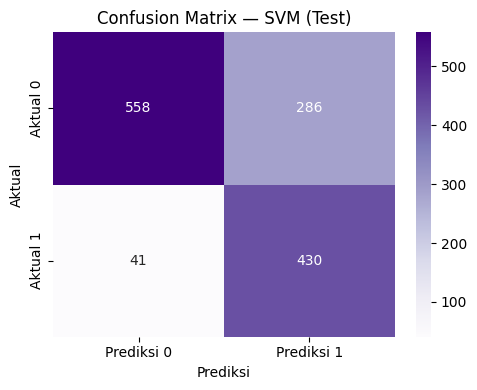

TN=558, FP=286, FN=41, TP=430


                 precision    recall  f1-score   support

Tidak hujan (0)       0.93      0.66      0.77       844
      Hujan (1)       0.60      0.91      0.72       471

       accuracy                           0.75      1315
      macro avg       0.77      0.79      0.75      1315
   weighted avg       0.81      0.75      0.76      1315



In [12]:
svm_final = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale",
                class_weight=best_svm["class_weight"]))
])
svm_final.fit(X_dev, y_dev)

svm_test_scores = svm_final.decision_function(X_test)
svm_test_pred = (svm_test_scores >= best_svm["threshold"]).astype(int)
svm_test_metrics = calculate_metrics(y_test, svm_test_pred, svm_test_scores)

print("SVM terpilih:", best_svm_name)
print("Threshold keputusan:", round(best_svm["threshold"], 4))
display(pd.DataFrame([svm_test_metrics]).T.rename(columns={0:"Nilai"}))
show_confusion_matrix(y_test, svm_test_pred, "Confusion Matrix — SVM (Test)")
print("\n")
print(classification_report(y_test, svm_test_pred,
                            target_names=["Tidak hujan (0)", "Hujan (1)"],
                            zero_division=0))

## **12. Fungsi membangun ANN**

In [13]:
def build_ann(input_dim):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.30),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.20),
        layers.Dense(1, activation="sigmoid")
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(),
        loss="binary_crossentropy"
    )
    return model

def balanced_class_weights(y_values):
    counts = pd.Series(y_values).value_counts().to_dict()
    n = len(y_values)
    k = len(counts)
    return {int(cls): n / (k * count) for cls, count in counts.items()}

## **13. ANN: 5-fold expanding-window validation**

ANN_unweighted - fold 1 selesai.
ANN_unweighted - fold 2 selesai.
ANN_unweighted - fold 3 selesai.
ANN_unweighted - fold 4 selesai.
ANN_unweighted - fold 5 selesai.

ANN_unweighted | threshold probabilitas = 0.1446


,Nilai
Accuracy,0.623744
Balanced Accuracy,0.701920
Precision_hujan,0.453181
Recall_hujan,0.914863
F1_hujan,0.606119
F2_hujan,0.760010
ROC_AUC,0.841086
Average_Precision,0.735268


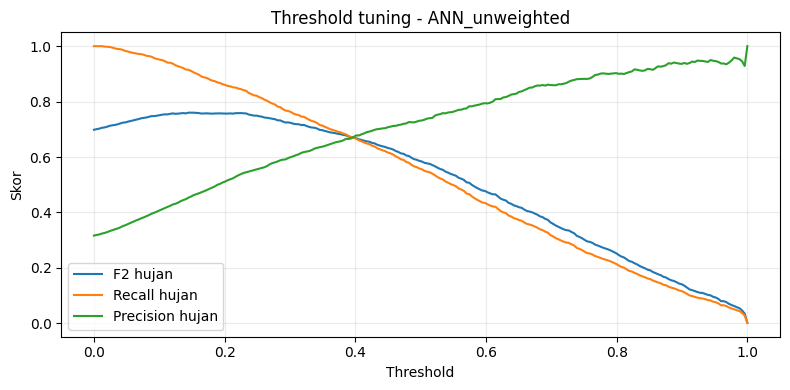

ANN_balanced - fold 1 selesai.
ANN_balanced - fold 2 selesai.
ANN_balanced - fold 3 selesai.
ANN_balanced - fold 4 selesai.
ANN_balanced - fold 5 selesai.

ANN_balanced | threshold probabilitas = 0.2553


,Nilai
Accuracy,0.560731
Balanced Accuracy,0.662222
Precision_hujan,0.414331
Recall_hujan,0.938672
F1_hujan,0.574901
F2_hujan,0.749079
ROC_AUC,0.828800
Average_Precision,0.715467


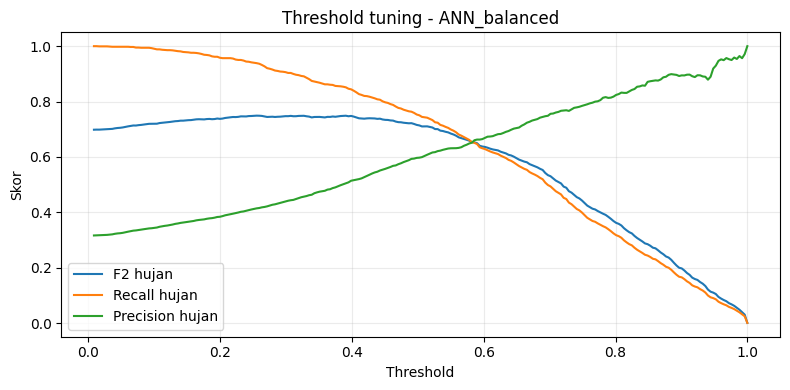

In [14]:
ann_results = {}

#2 perlakuan dibandingkan: tanpa dan dengan class_weight otomatis
for setting_name, use_weights in [
    ("ANN_unweighted", False),
    ("ANN_balanced", True)
]:
    oof_true, oof_scores = [], []

    for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_dev), start=1):
        X_fold_train = X_dev.iloc[tr_idx].copy()
        y_fold_train = y_dev.iloc[tr_idx].copy()
        X_fold_val = X_dev.iloc[val_idx].copy()
        y_fold_val = y_dev.iloc[val_idx].copy()

        # Validation internal: 15% bagian terakhir tiap training fold untuk early stopping.
        inner_split = int(len(X_fold_train) * 0.85)
        X_inner_train = X_fold_train.iloc[:inner_split]
        y_inner_train = y_fold_train.iloc[:inner_split]
        X_inner_val = X_fold_train.iloc[inner_split:]
        y_inner_val = y_fold_train.iloc[inner_split:]

        scaler = StandardScaler() #Scaler hanya di-fit pada bagian training internal.
        X_inner_train_sc = scaler.fit_transform(X_inner_train)
        X_inner_val_sc = scaler.transform(X_inner_val)
        X_fold_val_sc = scaler.transform(X_fold_val)

        model = build_ann(X_dev.shape[1])
        callbacks = [
            keras.callbacks.EarlyStopping(
                monitor="val_loss", patience=10,
                restore_best_weights=True
            )
        ]

        cw = balanced_class_weights(y_inner_train) if use_weights else None

        model.fit(
            X_inner_train_sc, y_inner_train,
            validation_data=(X_inner_val_sc, y_inner_val),
            epochs=100,
            batch_size=32,
            class_weight=cw,
            callbacks=callbacks,
            verbose=0
        )

        scores = model.predict(X_fold_val_sc, verbose=0).ravel()
        oof_true.extend(y_fold_val.tolist())
        oof_scores.extend(scores.tolist())

        print(f"{setting_name} - fold {fold} selesai.")

        del model
        keras.backend.clear_session()

    threshold, threshold_table = choose_threshold(oof_true, oof_scores)
    oof_pred = (np.asarray(oof_scores) >= threshold).astype(int)
    metrics = calculate_metrics(oof_true, oof_pred, np.asarray(oof_scores))

    ann_results[setting_name] = {
        "use_weights": use_weights,
        "threshold": threshold,
        "oof_true": np.asarray(oof_true),
        "oof_scores": np.asarray(oof_scores),
        "threshold_table": threshold_table,
        "cv_metrics": metrics
    }

    print(f"\n{setting_name} | threshold probabilitas = {threshold:.4f}")
    display(pd.DataFrame([metrics]).T.rename(columns={0:"Nilai"}))
    plot_threshold_curve(threshold_table, f"Threshold tuning - {setting_name}")

## **14. Memilih konfigurasi ANN berdasarkan validation**

In [15]:
best_ann_name = max(
    ann_results,
    key=lambda k: (
        ann_results[k]["cv_metrics"]["F2_hujan"],
        ann_results[k]["cv_metrics"]["Recall_hujan"]
    )
)
best_ann = ann_results[best_ann_name]
print("Konfigurasi ANN terpilih:", best_ann_name)
print("Threshold probabilitas terpilih:", (best_ann["threshold"]))
display(pd.DataFrame({k:v["cv_metrics"] for k,v in ann_results.items()}).T)

Konfigurasi ANN terpilih: ANN_unweighted
Threshold probabilitas terpilih: 0.14459367856134892


,Accuracy,Balanced Accuracy,Precision_hujan,Recall_hujan,F1_hujan,F2_hujan,ROC_AUC,Average_Precision
ANN_unweighted,0.623744,0.701920,0.453181,0.914863,0.606119,0.760010,0.841086,0.735268
ANN_balanced,0.560731,0.662222,0.414331,0.938672,0.574901,0.749079,0.828800,0.715467


## **15. Fit ANN terpilih dan evaluasi test 1x**

Epoch 1/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - loss: 0.5827 - val_loss: 0.4251
Epoch 2/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.5048 - val_loss: 0.4037
Epoch 3/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4906 - val_loss: 0.3899
Epoch 4/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4777 - val_loss: 0.3848
Epoch 5/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4654 - val_loss: 0.3769
Epoch 6/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4597 - val_loss: 0.3730
Epoch 7/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.4549 - val_loss: 0.3685
Epoch 8/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.4503 - val_loss: 0.3708
Epoch 9/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.4427 - val_loss: 0.3691
Epoch 10/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 0.4396 - val_loss: 0.3653
Epoch 11/100
140/140 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.4434 - val_loss: 0.3617
Epoch 12/100
140/140 ━━━━━━━━━━━━━━━━

,Nilai
Accuracy,0.733080
Balanced Accuracy,0.772826
Precision_hujan,0.581081
Recall_hujan,0.912951
F1_hujan,0.710157
F2_hujan,0.819360
ROC_AUC,0.894132
Average_Precision,0.830366


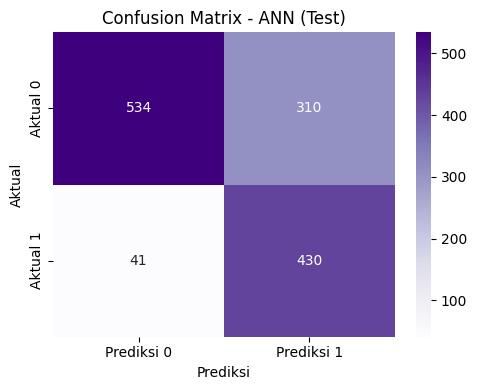

TN=534, FP=310, FN=41, TP=430


                 precision    recall  f1-score   support

Tidak hujan (0)       0.93      0.63      0.75       844
      Hujan (1)       0.58      0.91      0.71       471

       accuracy                           0.73      1315
      macro avg       0.75      0.77      0.73      1315
   weighted avg       0.80      0.73      0.74      1315



In [16]:
# Split internal kronologis untuk early stopping.
ann_inner_split = int(len(X_dev) * 0.85)
X_ann_train = X_dev.iloc[:ann_inner_split]
y_ann_train = y_dev.iloc[:ann_inner_split]
X_ann_val = X_dev.iloc[ann_inner_split:]
y_ann_val = y_dev.iloc[ann_inner_split:]

ann_scaler_final = StandardScaler()
X_ann_train_sc = ann_scaler_final.fit_transform(X_ann_train)
X_ann_val_sc = ann_scaler_final.transform(X_ann_val)
X_test_ann_sc = ann_scaler_final.transform(X_test)

ann_final = build_ann(X_dev.shape[1])
ann_cw_final = balanced_class_weights(y_ann_train) if best_ann["use_weights"] else None

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)

history = ann_final.fit(
    X_ann_train_sc, y_ann_train,
    validation_data=(X_ann_val_sc, y_ann_val),
    epochs=100,
    batch_size=32,
    class_weight=ann_cw_final,
    callbacks=[early_stop],
    verbose=1
)

ann_test_scores = ann_final.predict(X_test_ann_sc, verbose=0).ravel()
ann_test_pred = (ann_test_scores >= best_ann["threshold"]).astype(int)
ann_test_metrics = calculate_metrics(y_test, ann_test_pred, ann_test_scores)

print("\nANN terpilih:", best_ann_name)
print("Threshold probabilitas:", round(best_ann["threshold"],4))
display(pd.DataFrame([ann_test_metrics]).T.rename(columns={0:"Nilai"}))
show_confusion_matrix(y_test, ann_test_pred, "Confusion Matrix - ANN (Test)")
print("\n")
print(classification_report(y_test, ann_test_pred,
                            target_names=["Tidak hujan (0)", "Hujan (1)"],
                            zero_division=0))

## **16. Grafik training ANN**

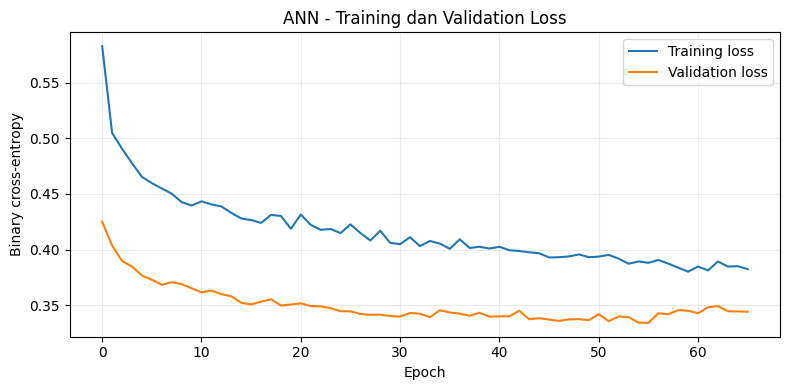

In [17]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("ANN - Training dan Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## **17. Perbandingan baseline, SVM, dan ANN pada test set**

,Accuracy,Balanced Accuracy,Precision_hujan,Recall_hujan,F1_hujan,F2_hujan,ROC_AUC,Average_Precision
Baseline,0.6418,0.5000,0.0000,0.000,0.0000,0.0000,NaN,NaN
SVM,0.7513,0.7870,0.6006,0.913,0.7245,0.8269,0.8879,0.8255
ANN,0.7331,0.7728,0.5811,0.913,0.7102,0.8194,0.8941,0.8304


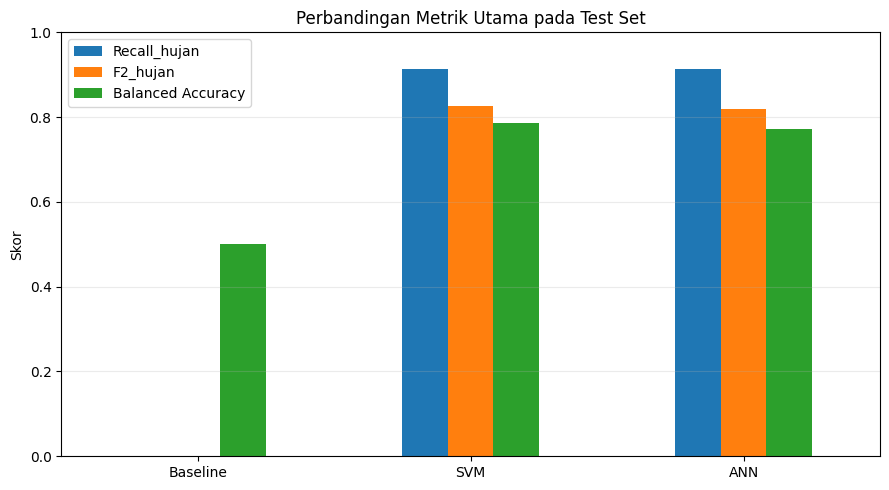

In [18]:
comparison = pd.DataFrame({
    "Baseline": baseline_test_metrics,
    "SVM": svm_test_metrics,
    "ANN": ann_test_metrics
}).T

display(comparison.round(4))

main_metrics = ["Recall_hujan", "F2_hujan", "Balanced Accuracy"]
comparison[main_metrics].plot(kind="bar", figsize=(9, 5))
plt.title("Perbandingan Metrik Utama pada Test Set")
plt.ylabel("Skor")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## **18. Perbandingan confusion matrix**

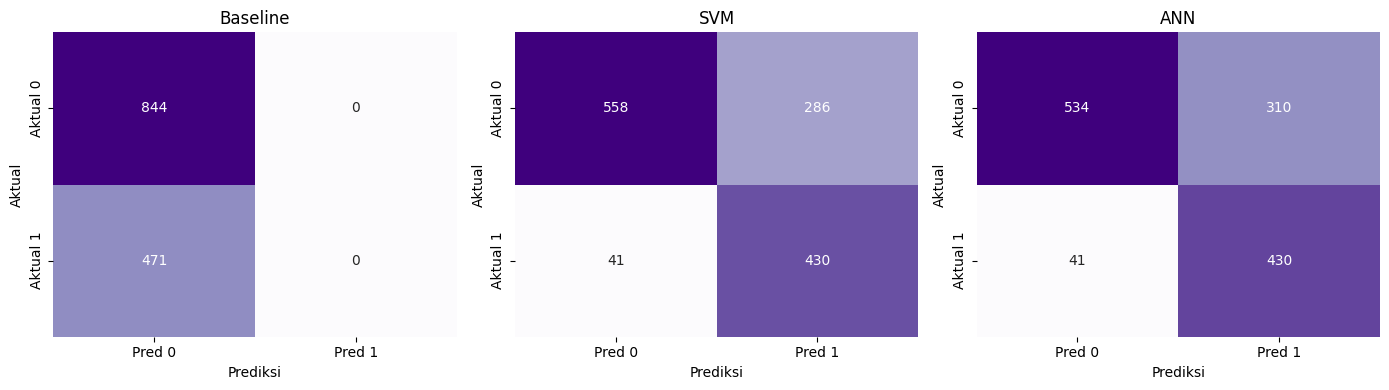

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
predictions = [
    ("Baseline", baseline_test_pred),
    ("SVM", svm_test_pred),
    ("ANN", ann_test_pred)
]
for ax, (name, pred) in zip(axes, predictions):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", cbar=False,
                xticklabels=["Pred 0", "Pred 1"],
                yticklabels=["Aktual 0", "Aktual 1"], ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
plt.tight_layout()
plt.show()

## **19. Analisis khusus FN dan FP**
- FN: hujan yang diprediksi tidak hujan.
- FP: tidak hujan yang diprediksi hujan.

In [20]:
def error_counts(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"TN": tn, "FP": fp, "FN": fn, "TP": tp}

error_comparison = pd.DataFrame({
    "Baseline": error_counts(y_test, baseline_test_pred),
    "SVM": error_counts(y_test, svm_test_pred),
    "ANN": error_counts(y_test, ann_test_pred)
}).T

display(error_comparison)
print("\nInterpretasi fokus:")
print("- FN lebih kecil berarti lebih sedikit kejadian hujan yang terlewat.")
print("- FP lebih besar berarti lebih banyak peringatan hujan palsu.")
print("- Penurunan FN perlu dibaca bersama perubahan FP dan Precision.")

,TN,FP,FN,TP
Baseline,844,0,471,0
SVM,558,286,41,430
ANN,534,310,41,430



Interpretasi fokus:
- FN lebih kecil berarti lebih sedikit kejadian hujan yang terlewat.
- FP lebih besar berarti lebih banyak peringatan hujan palsu.
- Penurunan FN perlu dibaca bersama perubahan FP dan Precision.


## **20. Ringkasan konfigurasi dan hasil**

In [21]:
summary = pd.DataFrame([
    {
        "Model": "Baseline",
        "Konfigurasi": "Most frequent",
        "Threshold": "-",
        **baseline_test_metrics
    },
    {
        "Model": "SVM",
        "Konfigurasi": best_svm_name,
        "Threshold": round(best_svm["threshold"], 5),
        **svm_test_metrics
    },
    {
        "Model": "ANN",
        "Konfigurasi": best_ann_name,
        "Threshold": round(best_ann["threshold"], 5),
        **ann_test_metrics
    }
])
display(summary.round(4))

,Model,Konfigurasi,Threshold,Accuracy,Balanced Accuracy,Precision_hujan,Recall_hujan,F1_hujan,F2_hujan,ROC_AUC,Average_Precision
0,Baseline,Most frequent,-,0.6418,0.5000,0.0000,0.000,0.0000,0.0000,NaN,NaN
1,SVM,SVM_balanced,-0.58164,0.7513,0.7870,0.6006,0.913,0.7245,0.8269,0.8879,0.8255
2,ANN,ANN_unweighted,0.14459,0.7331,0.7728,0.5811,0.913,0.7102,0.8194,0.8941,0.8304


## **21. Simpan hasil evaluasi**

In [22]:
from google.colab import files

comparison.to_csv("perbandingan_metrik_test.csv", index=True)
error_comparison.to_csv("perbandingan_confusion_matrix_test.csv", index=True)
summary.to_csv("ringkasan_hasil_proyek.csv", index=False)

print("File hasil evaluasi berhasil disimpan.")
files.download("perbandingan_metrik_test.csv")
files.download("perbandingan_confusion_matrix_test.csv")
files.download("ringkasan_hasil_proyek.csv")

File hasil evaluasi berhasil disimpan.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **22. Visualisasi**

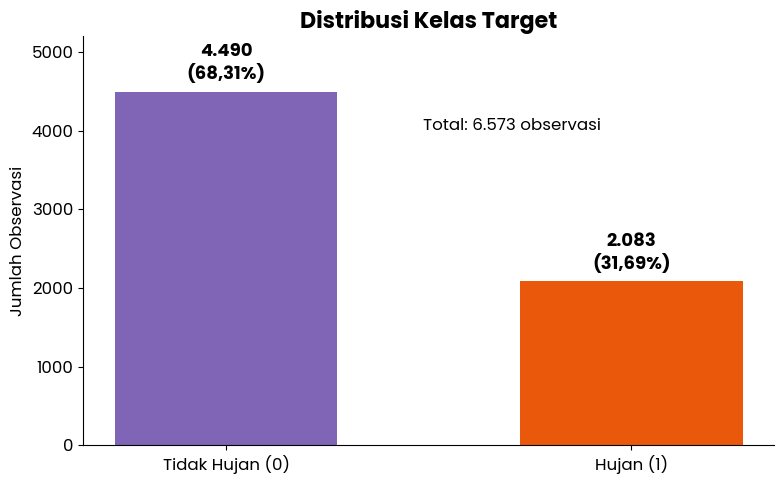

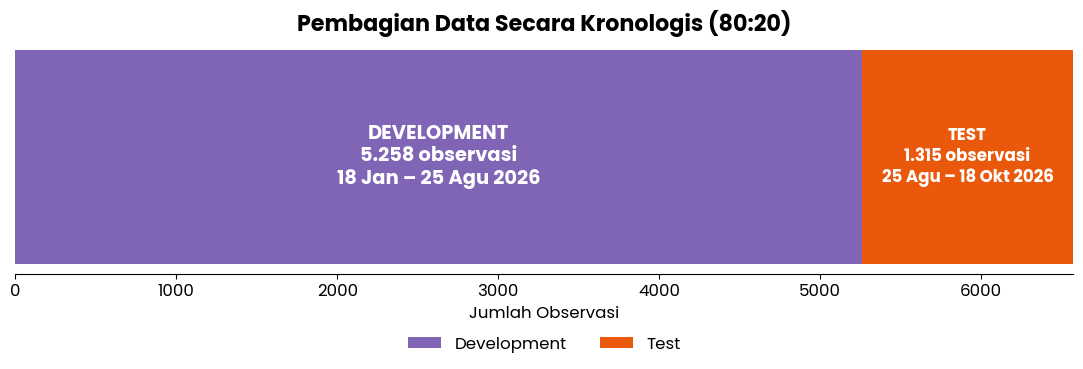

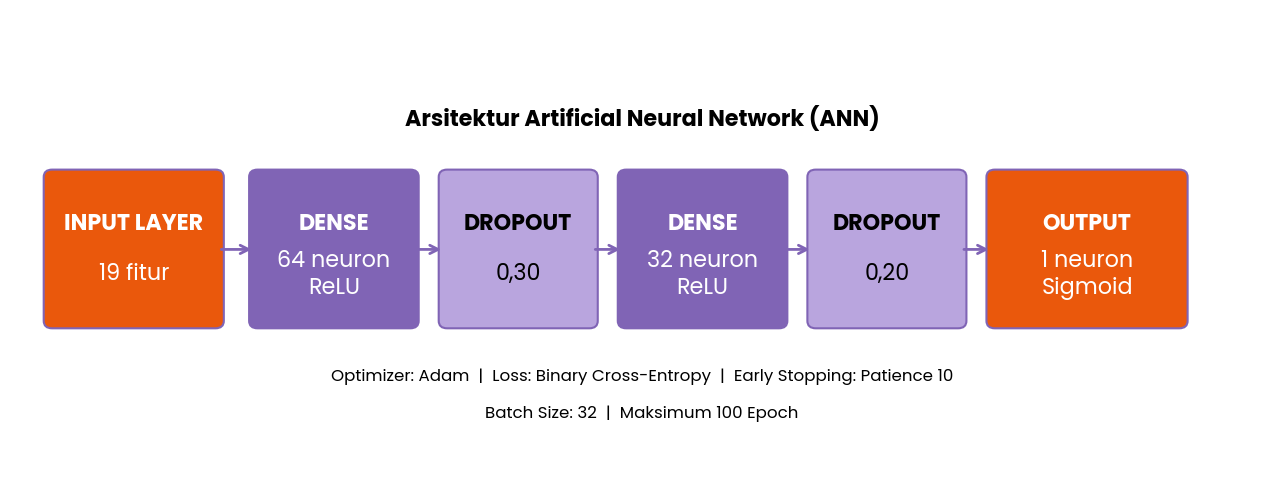

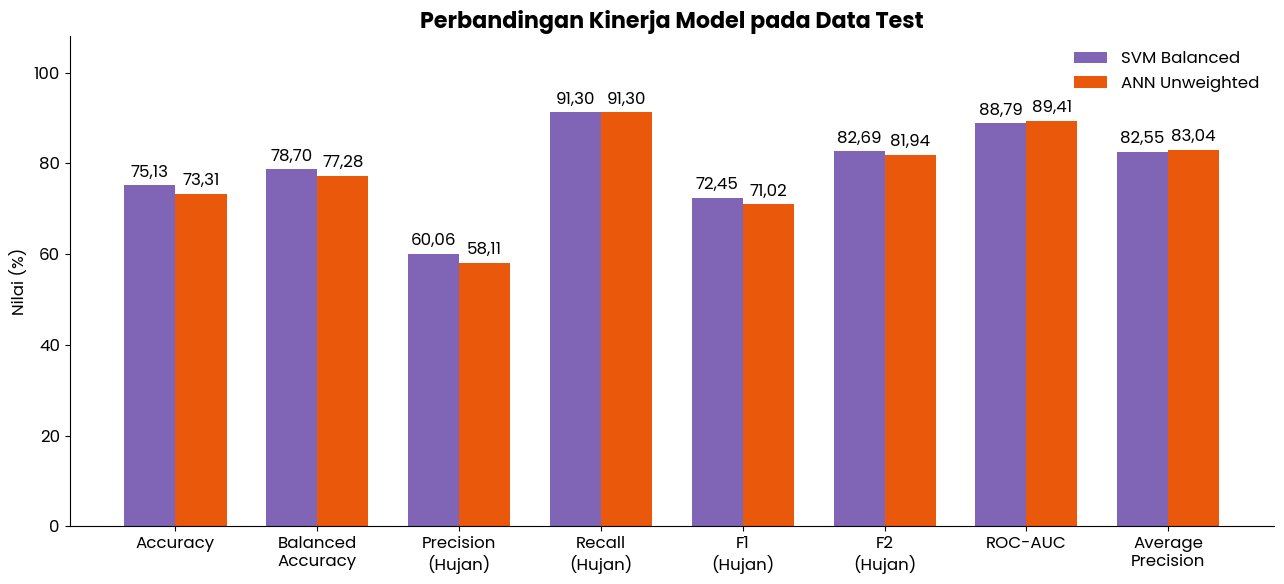

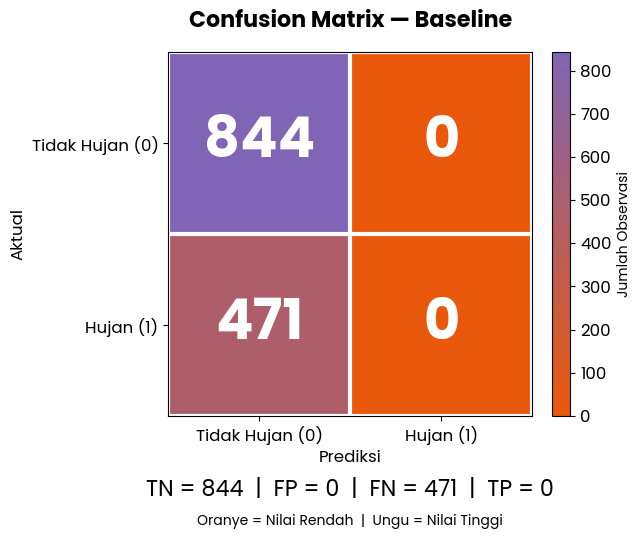

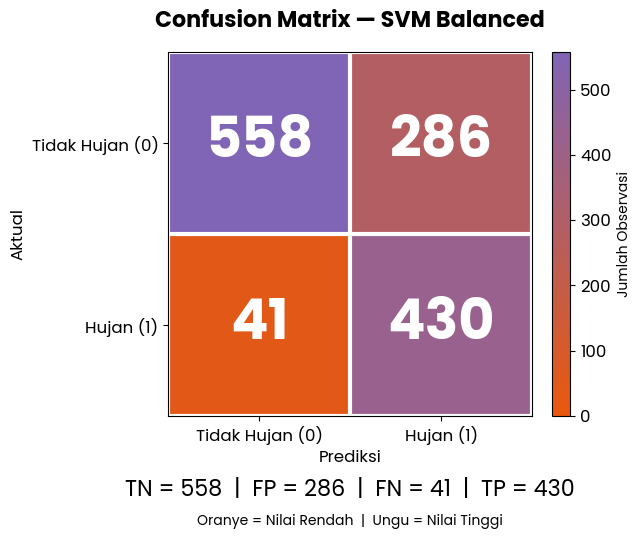

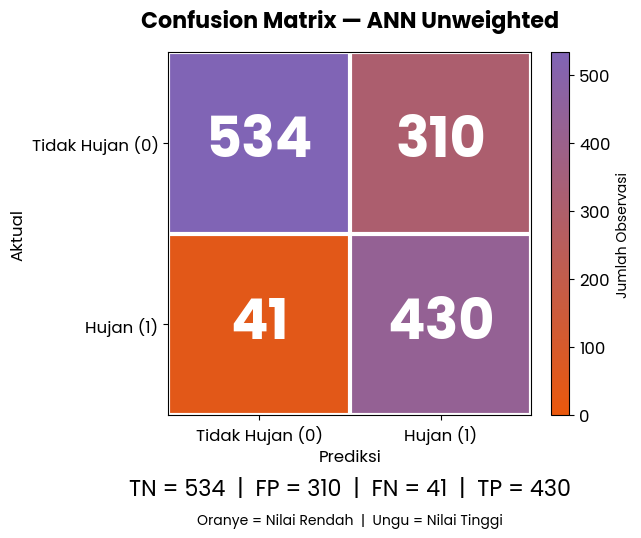

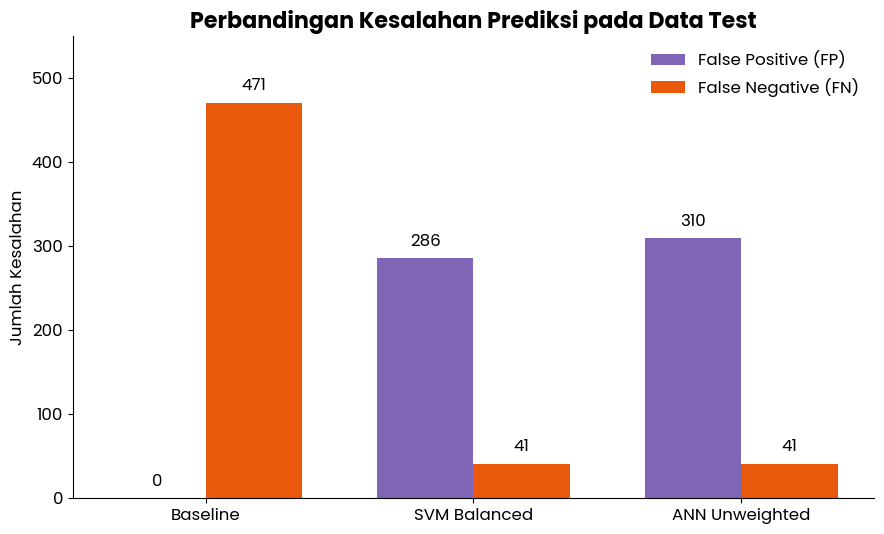

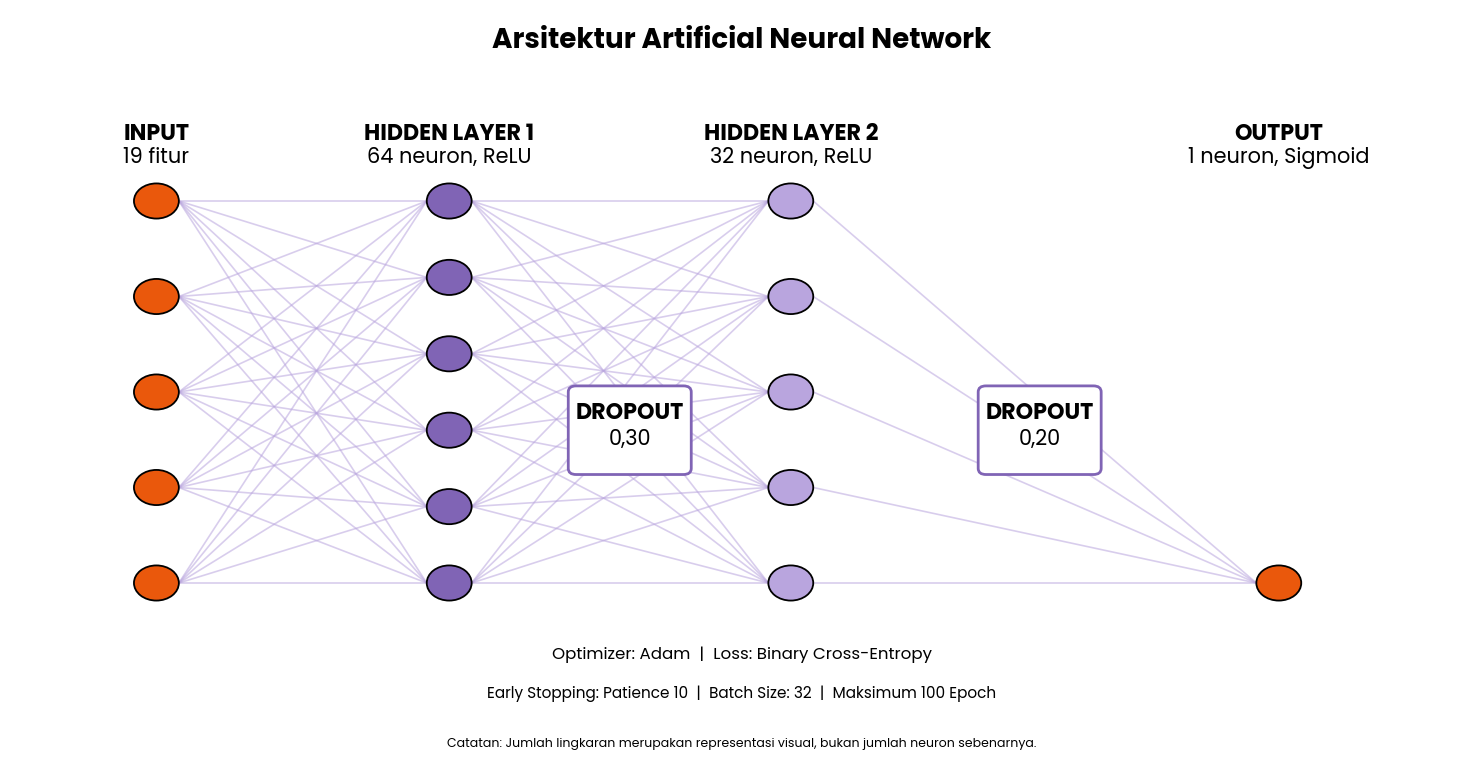

Explained variance ratio:
PC1: 32.08%
PC2: 10.27%
Total variasi yang dijelaskan: 42.35%


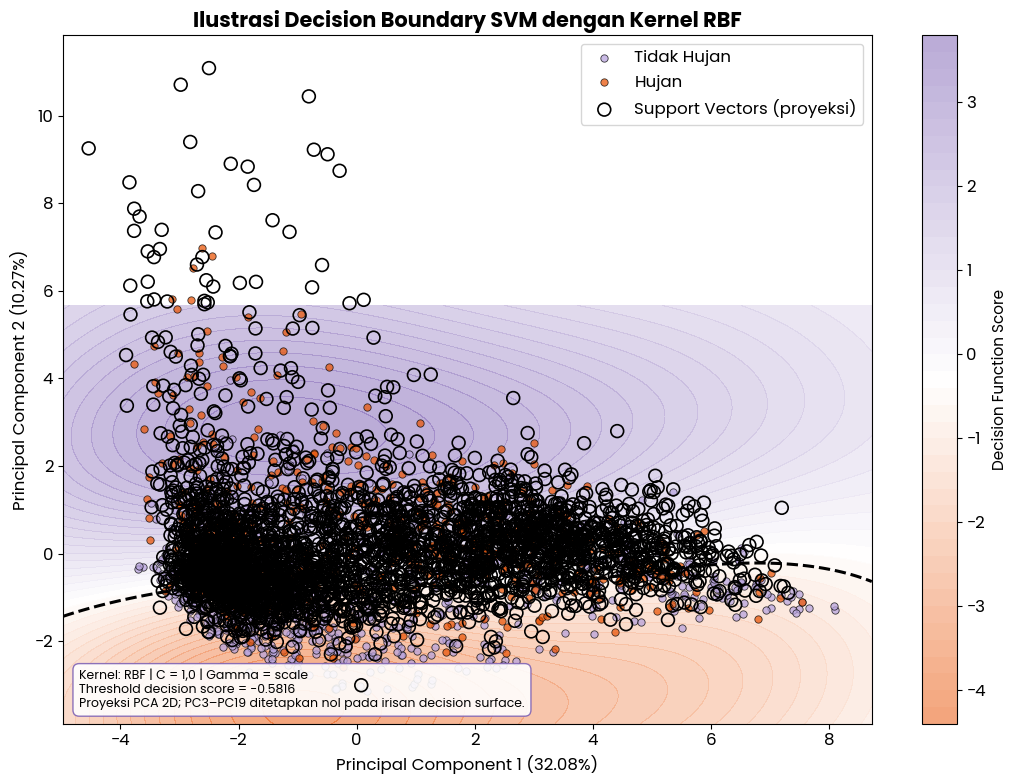

In [23]:
# ============================================================
# 1. KONFIGURASI WARNA, PENYIMPANAN, DAN FORMAT LOKAL
# ============================================================

UNGU = "#8064B5"
UNGU_MUDA = "#B9A5DE"
ORANYE = "#EA580C"
OUTPUT_DIR = "/content/visualisasi_uas_sml"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Pengaturan umum grafik
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Poppins"],
    "font.size": 12,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "figure.facecolor": "white",
    "axes.facecolor": "white"
})

# Fungsi pembantu untuk format angka Indonesia (Ribuan dengan titik, desimal dengan koma)
def format_id(nilai, desimal=0):
    if desimal == 0:
        return f"{int(nilai):,}".replace(",", ".")
    else:
        # Format desimal menggunakan pembatas sementara agar tidak saling bertabrakan saat di-replace
        formatted = f"{nilai:,.{desimal}f}"
        # Ganti "," (ribuan) menjadi "." dan "." (desimal) menjadi ","
        placeholder = formatted.replace(",", "placeholder_ribuan")
        placeholder = placeholder.replace(".", ",")
        return placeholder.replace("placeholder_ribuan", ".")

# ============================================================
# 2. VISUALISASI 1 — DISTRIBUSI KELAS TARGET
# ============================================================

labels = ["Tidak Hujan (0)", "Hujan (1)"]
counts = [4490, 2083]

total = sum(counts)
percentages = [x / total * 100 for x in counts]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    labels,
    counts,
    color=[UNGU, ORANYE],
    width=0.55
)

ax.set_title("Distribusi Kelas Target")
ax.set_ylabel("Jumlah Observasi")
ax.set_ylim(0, 5200)

for bar, count, pct in zip(bars, counts, percentages):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 100,
        f"{format_id(count)}\n({format_id(pct, desimal=2)}%)",
        ha="center",
        va="bottom",
        fontsize=13,
        fontweight="bold"
    )

ax.text(
    0.75, 0.8,
    f"Total: {format_id(total)} observasi",
    transform=ax.transAxes,
    ha="right",
    va="top"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    f"{OUTPUT_DIR}/01_distribusi_kelas.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()


# ============================================================
# 3. VISUALISASI 2 — PEMBAGIAN DATA KRONOLOGIS
# ============================================================

development = 5258
test = 1315
total_data = development + test

fig, ax = plt.subplots(figsize=(11, 4))

ax.barh(
    ["Dataset"],
    [development],
    color=UNGU,
    label="Development"
)

ax.barh(
    ["Dataset"],
    [test],
    left=[development],
    color=ORANYE,
    label="Test"
)

ax.set_xlim(0, total_data)
ax.set_xlabel("Jumlah Observasi")
ax.set_title("Pembagian Data Secara Kronologis (80:20)")
ax.set_yticks([])

# Label development
ax.text(
    development / 2,
    0,
    f"DEVELOPMENT\n{format_id(development)} observasi\n18 Jan – 25 Agu 2026",
    ha="center",
    va="center",
    color="white",
    fontsize=14,
    fontweight="bold"
)

# Label test
ax.text(
    development + test / 2,
    0,
    f"TEST\n{format_id(test)} observasi\n25 Agu – 18 Okt 2026",
    ha="center",
    va="center",
    color="white",
    fontsize=12,
    fontweight="bold"
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.2),
    ncol=2,
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

plt.tight_layout()
plt.savefig(
    f"{OUTPUT_DIR}/02_pembagian_data_kronologis.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()


# ============================================================
# 4. VISUALISASI 3 — ARSITEKTUR ANN
# ============================================================

fig, ax = plt.subplots(figsize=(13, 5))

ax.set_xlim(0, 12)
ax.set_ylim(0, 5)
ax.axis("off")

nodes = [
    (0.4, 1.65, 1.55, 1.55, "INPUT LAYER", "19 fitur"),
    (2.35, 1.65, 1.45, 1.55, "DENSE", "64 neuron\nReLU"),
    (4.15, 1.65, 1.35, 1.55, "DROPOUT", "0,30"),
    (5.85, 1.65, 1.45, 1.55, "DENSE", "32 neuron\nReLU"),
    (7.65, 1.65, 1.35, 1.55, "DROPOUT", "0,20"),
    (9.35, 1.65, 1.75, 1.55, "OUTPUT", "1 neuron\nSigmoid")
]

node_colors = [
    ORANYE,
    UNGU,
    UNGU_MUDA,
    UNGU,
    UNGU_MUDA,
    ORANYE
]

for (x, y, w, h, title, detail), color in zip(nodes, node_colors):

    box = FancyBboxPatch(
        (x, y),
        w,
        h,
        boxstyle="round,pad=0.08",
        linewidth=1.5,
        edgecolor=UNGU,
        facecolor=color
    )

    ax.add_patch(box)

    text_color = "black" if color == UNGU_MUDA else "white"

    ax.text(
        x + w / 2,
        y + h * 0.67,
        title,
        ha="center",
        va="center",
        fontsize=16,
        fontweight="bold",
        color=text_color
    )

    ax.text(
        x + w / 2,
        y + h * 0.32,
        detail,
        ha="center",
        va="center",
        fontsize=16,
        color=text_color
    )

# Panah antarlayer
for i in range(len(nodes) - 1):

    x1 = nodes[i][0] + nodes[i][2]
    x2 = nodes[i + 1][0]

    arrow = FancyArrowPatch(
        (x1 + 0.03, 2.42),
        (x2 - 0.03, 2.42),
        arrowstyle="->",
        mutation_scale=15,
        linewidth=2,
        color=UNGU
    )

    ax.add_patch(arrow)

ax.text(
    6,
    3.75,
    "Arsitektur Artificial Neural Network (ANN)",
    ha="center",
    fontsize=16,
    fontweight="bold",
    color="black"
)

ax.text(
    6,
    1,
    "Optimizer: Adam  |  Loss: Binary Cross-Entropy  |  Early Stopping: Patience 10",
    ha="center",
    fontsize=12
)

ax.text(
    6,
    0.6,
    "Batch Size: 32  |  Maksimum 100 Epoch",
    ha="center",
    fontsize=12
)

plt.tight_layout()
plt.savefig(
    f"{OUTPUT_DIR}/03_arsitektur_ann.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()


# ============================================================
# 5. VISUALISASI 4 — PERBANDINGAN METRIK MODEL
# ============================================================

metrics = [
    "Accuracy",
    "Balanced\nAccuracy",
    "Precision\n(Hujan)",
    "Recall\n(Hujan)",
    "F1\n(Hujan)",
    "F2\n(Hujan)",
    "ROC-AUC",
    "Average\nPrecision"
]

# Menambahkan nilai ROC-AUC dan Average Precision sesuai data test pipeline
svm = [75.13, 78.70, 60.06, 91.30, 72.45, 82.69, 88.79, 82.55]
ann = [73.31, 77.28, 58.11, 91.30, 71.02, 81.94, 89.41, 83.04]

x = np.arange(len(metrics))
width = 0.36

fig, ax = plt.subplots(figsize=(13, 6))

bars1 = ax.bar(
    x - width / 2,
    svm,
    width,
    label="SVM Balanced",
    color=UNGU
)

bars2 = ax.bar(
    x + width / 2,
    ann,
    width,
    label="ANN Unweighted",
    color=ORANYE
)

ax.set_title("Perbandingan Kinerja Model pada Data Test")
ax.set_ylabel("Nilai (%)")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 108)

ax.legend(frameon=False)

for bars in [bars1, bars2]:
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f"{format_id(bar.get_height(), desimal=2)}",
            ha="center",
            va="bottom",
            fontsize=12
        )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    f"{OUTPUT_DIR}/04_perbandingan_metrik_test.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()


# ============================================================
# 6. FUNGSI PEMBUATAN CONFUSION MATRIX
# ============================================================

from matplotlib.colors import LinearSegmentedColormap

def buat_confusion_matrix(
    filename,
    title,
    tn,
    fp,
    fn,
    tp
):

    cm = np.array([
        [tn, fp],
        [fn, tp]
    ])

    # Colormap gradasi ORANYE -> UNGU
    # Nilai rendah = Oranye
    # Nilai tinggi = Ungu
    cmap = LinearSegmentedColormap.from_list(
        "Orange_Purple",
        [ORANYE, UNGU]
    )

    fig, ax = plt.subplots(figsize=(7, 5.8))

    # Membuat matriks berdasarkan nilai aktual
    im = ax.imshow(
        cm,
        cmap=cmap,
        vmin=0,
        vmax=cm.max()
    )

    # Judul dan label sumbu
    ax.set_title(title, pad=18)

    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Tidak Hujan (0)", "Hujan (1)"])

    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Tidak Hujan (0)", "Hujan (1)"])

    # Menampilkan nilai di dalam setiap sel
    for i in range(2):
        for j in range(2):

            value = cm[i, j]

            ax.text(
                j,
                i,
                f"{format_id(value)}",
                ha="center",
                va="center",
                fontsize=40,
                fontweight="bold",
                color="white"
            )

    # Garis pemisah antarsel
    ax.set_xticks(
        np.arange(-0.5, 2, 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, 2, 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="white",
        linestyle="-",
        linewidth=3
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False
    )

    # Colorbar / meteran warna
    cbar = fig.colorbar(
        im,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )

    cbar.set_label(
        "Jumlah Observasi",
        fontsize=10
    )

    # Keterangan TN, FP, FN, TP
    ax.text(
        0.5,
        -0.22,
        f"TN = {format_id(tn)}  |  FP = {format_id(fp)}  |  FN = {format_id(fn)}  |  TP = {format_id(tp)}",
        transform=ax.transAxes,
        ha="center",
        fontsize=16
    )

    ax.text(
        0.5,
        -0.30,
        "Oranye = Nilai Rendah  |  Ungu = Nilai Tinggi",
        transform=ax.transAxes,
        ha="center",
        fontsize=10
    )

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/{filename}",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


# ============================================================
# 7. VISUALISASI 5 — CONFUSION MATRIX BASELINE
# ============================================================

buat_confusion_matrix(
    filename="05_confusion_matrix_baseline.png",
    title="Confusion Matrix — Baseline",
    tn=844,
    fp=0,
    fn=471,
    tp=0
)


# ============================================================
# 8. VISUALISASI 6 — CONFUSION MATRIX SVM
# ============================================================

buat_confusion_matrix(
    filename="06_confusion_matrix_svm.png",
    title="Confusion Matrix — SVM Balanced",
    tn=558,
    fp=286,
    fn=41,
    tp=430
)


# ============================================================
# 9. VISUALISASI 7 — CONFUSION MATRIX ANN
# ============================================================

buat_confusion_matrix(
    filename="07_confusion_matrix_ann.png",
    title="Confusion Matrix — ANN Unweighted",
    tn=534,
    fp=310,
    fn=41,
    tp=430
)


# ============================================================
# 10. VISUALISASI 8 — PERBANDINGAN FP DAN FN
# ============================================================

models = [
    "Baseline",
    "SVM Balanced",
    "ANN Unweighted"
]

fp = [0, 286, 310]
fn = [471, 41, 41]

x = np.arange(len(models))
width = 0.36

fig, ax = plt.subplots(figsize=(9, 5.5))

bars1 = ax.bar(
    x - width / 2,
    fp,
    width,
    label="False Positive (FP)",
    color=UNGU
)

bars2 = ax.bar(
    x + width / 2,
    fn,
    width,
    label="False Negative (FN)",
    color=ORANYE
)

ax.set_title("Perbandingan Kesalahan Prediksi pada Data Test")
ax.set_ylabel("Jumlah Kesalahan")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 550)

ax.legend(frameon=False)

for bars in [bars1, bars2]:
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 10,
            f"{format_id(bar.get_height())}",
            ha="center",
            va="bottom",
            fontsize=12
        )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    f"{OUTPUT_DIR}/08_perbandingan_fp_fn.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()


# ============================================================
# VISUALISASI ARSITEKTUR ANN
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import FancyBboxPatch, Circle, FancyArrowPatch

# Palet warna
UNGU = "#8064B5"
UNGU_MUDA = "#B9A5DE"
ORANYE = "#EA580C"
HITAM = "#000000"
PUTIH = "#FFFFFF"

fig, ax = plt.subplots(figsize=(15, 8))

ax.set_xlim(0, 15)
ax.set_ylim(0, 10)
ax.axis("off")

# ------------------------------------------------------------
# Judul
# ------------------------------------------------------------

ax.text(
    7.5, 9.5,
    "Arsitektur Artificial Neural Network",
    ha="center",
    fontsize=20,
    fontweight="bold",
    color=HITAM
)

# ------------------------------------------------------------
# Posisi neuron representatif
# Jumlah lingkaran bukan jumlah neuron sebenarnya.
# ------------------------------------------------------------

layers = {
    "input": {
        "x": 1.5,
        "neurons": 5,
        "color": ORANYE,
        "label": "INPUT",
        "detail": "19 fitur"
    },
    "dense1": {
        "x": 4.5,
        "neurons": 6,
        "color": UNGU,
        "label": "HIDDEN LAYER 1",
        "detail": "64 neuron, ReLU"
    },
    "dense2": {
        "x": 8.0,
        "neurons": 5,
        "color": UNGU_MUDA,
        "label": "HIDDEN LAYER 2",
        "detail": "32 neuron, ReLU"
    },
    "output": {
        "x": 13,
        "neurons": 1,
        "color": ORANYE,
        "label": "OUTPUT",
        "detail": "1 neuron, Sigmoid"
    }
}

y_positions = {}

for name, layer in layers.items():

    x = layer["x"]
    n = layer["neurons"]

    ys = np.linspace(2.5, 7.5, n)

    y_positions[name] = ys

    # Label layer
    ax.text(
        x, 8.3,
        layer["label"],
        ha="center",
        fontsize=16,
        fontweight="bold"
    )

    ax.text(
        x, 8,
        layer["detail"],
        ha="center",
        fontsize=15
    )

    # Neuron representatif
    for y in ys:

        circle = Circle(
            (x, y),
            radius=0.23,
            facecolor=layer["color"],
            edgecolor=HITAM,
            linewidth=1.3,
            zorder=3
        )

        ax.add_patch(circle)


# ------------------------------------------------------------
# Koneksi antarneuron
# ------------------------------------------------------------

connections = [
    ("input", "dense1"),
    ("dense1", "dense2"),
    ("dense2", "output")
]

for source, target in connections:

    x1 = layers[source]["x"]
    x2 = layers[target]["x"]

    for y1 in y_positions[source]:
        for y2 in y_positions[target]:

            ax.plot(
                [x1 + 0.23, x2 - 0.23],
                [y1, y2],
                color=UNGU_MUDA,
                alpha=0.55,
                linewidth=1.2,
                zorder=1
            )


# ------------------------------------------------------------
# Dropout 1
# ------------------------------------------------------------

drop1 = FancyBboxPatch(
    (5.8, 4.0),
    1.1,
    1.0,
    boxstyle="round,pad=0.08",
    facecolor=PUTIH,
    edgecolor=UNGU,
    linewidth=2
)

ax.add_patch(drop1)

ax.text(
    6.35, 4.65,
    "DROPOUT",
    ha="center",
    fontsize=16,
    fontweight="bold"
)

ax.text(
    6.35, 4.3,
    "0,30",
    ha="center",
    fontsize=15
)


# ------------------------------------------------------------
# Dropout 2
# ------------------------------------------------------------

drop2 = FancyBboxPatch(
    (10.0, 4.0),
    1.1,
    1.0,
    boxstyle="round,pad=0.08",
    facecolor=PUTIH,
    edgecolor=UNGU,
    linewidth=2
)

ax.add_patch(drop2)

ax.text(
    10.55, 4.65,
    "DROPOUT",
    ha="center",
    fontsize=16,
    fontweight="bold"
)

ax.text(
    10.55, 4.3,
    "0,20",
    ha="center",
    fontsize=15
)


# ------------------------------------------------------------
# Keterangan
# ------------------------------------------------------------

ax.text(
    7.5, 1.5,
    "Optimizer: Adam  |  Loss: Binary Cross-Entropy",
    ha="center",
    fontsize=12
)

ax.text(
    7.5, 1.0,
    "Early Stopping: Patience 10  |  Batch Size: 32  |  Maksimum 100 Epoch",
    ha="center",
    fontsize=11
)

ax.text(
    7.5, 0.35,
    "Catatan: Jumlah lingkaran merupakan representasi visual, bukan jumlah neuron sebenarnya.",
    ha="center",
    fontsize=9,
    color=HITAM
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/09_arsitektur_ann_detail.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=PUTIH
)

plt.show()
plt.close()


# ============================================================
# VISUALISASI SVM RBF DENGAN PROYEKSI PCA 2D
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# 1. PALET WARNA
# ------------------------------------------------------------

UNGU = "#8064B5"
UNGU_MUDA = "#B9A5DE"
ORANYE = "#EA580C"
HITAM = "#000000"
PUTIH = "#FFFFFF"

# Gradasi area decision score:
# Nilai negatif -> Oranye
# Nilai positif -> Ungu

cmap_rbf = LinearSegmentedColormap.from_list(
    "Orange_Purple_RBF",
    [ORANYE, PUTIH, UNGU]
)

# ------------------------------------------------------------
# 2. MENGAMBIL SCALER DAN SVM DARI PIPELINE FINAL
# ------------------------------------------------------------

scaler_svm = svm_final.named_steps["scaler"]
model_svm = svm_final.named_steps["svm"]

# Standardisasi development dan test
X_dev_scaled = scaler_svm.transform(X_dev)
X_test_scaled = scaler_svm.transform(X_test)

# ------------------------------------------------------------
# 3. PCA UNTUK PROYEKSI 19 FITUR KE 2 DIMENSI
# ------------------------------------------------------------

pca = PCA(n_components=2)

# PCA hanya di-fit menggunakan development data
X_dev_pca = pca.fit_transform(X_dev_scaled)

# Test dan support vectors menggunakan transform yang sama
X_test_pca = pca.transform(X_test_scaled)

support_vectors = model_svm.support_vectors_
support_vectors_pca = pca.transform(support_vectors)

print("Explained variance ratio:")
print(f"PC1: {pca.explained_variance_ratio_[0]*100:.2f}%")
print(f"PC2: {pca.explained_variance_ratio_[1]*100:.2f}%")
print(
    "Total variasi yang dijelaskan:",
    f"{pca.explained_variance_ratio_.sum()*100:.2f}%"
)

# ------------------------------------------------------------
# 4. MEMBUAT GRID PADA BIDANG PCA
# ------------------------------------------------------------

x_min, x_max = np.percentile(X_test_pca[:, 0], [1, 99])
y_min, y_max = np.percentile(X_test_pca[:, 1], [1, 99])

x_margin = (x_max - x_min) * 0.15
y_margin = (y_max - y_min) * 0.15

x_min -= x_margin
x_max += x_margin
y_min -= y_margin
y_max += y_margin

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

# ------------------------------------------------------------
# 5. REKONSTRUKSI GRID KE RUANG 19 FITUR
# ------------------------------------------------------------

# grid_pca diinisialisasi hanya dengan 2 kolom agar sesuai dengan n_components=2 pada PCA
grid_pca = np.zeros((xx.size, 2))

grid_pca[:, 0] = xx.ravel()
grid_pca[:, 1] = yy.ravel()

grid_scaled = pca.inverse_transform(grid_pca)

# Menghitung decision score dari SVM aktual
Z = model_svm.decision_function(grid_scaled)

Z = Z.reshape(xx.shape)

# ------------------------------------------------------------
# 6. THRESHOLD FINAL SVM
# ------------------------------------------------------------

threshold_svm = best_svm["threshold"]

# ------------------------------------------------------------
# 7. VISUALISASI
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 8))

# Area berdasarkan decision score
contour = ax.contourf(
    xx,
    yy,
    Z,
    levels=40,
    cmap=cmap_rbf,
    alpha=0.55
)

# Batas keputusan berdasarkan threshold final
boundary = ax.contour(
    xx,
    yy,
    Z,
    levels=[threshold_svm],
    colors=HITAM,
    linewidths=2.2
)

# Data test kelas 0
mask_0 = np.asarray(y_test) == 0

# Data test kelas 1
mask_1 = np.asarray(y_test) == 1

ax.scatter(
    X_test_pca[mask_0, 0],
    X_test_pca[mask_0, 1],
    color=UNGU_MUDA,
    edgecolor=HITAM,
    linewidth=0.6,
    s=28,
    alpha=0.75,
    label="Tidak Hujan"
)

ax.scatter(
    X_test_pca[mask_1, 0],
    X_test_pca[mask_1, 1],
    color=ORANYE,
    edgecolor=HITAM,
    linewidth=0.6,
    s=28,
    alpha=0.75,
    label="Hujan"
)

# Support vectors dari model aktual
ax.scatter(
    support_vectors_pca[:, 0],
    support_vectors_pca[:, 1],
    facecolors="none",
    edgecolors=HITAM,
    linewidths=1.2,
    s=85,
    marker="o",
    label="Support Vectors (proyeksi)",
    zorder=5
)

# ------------------------------------------------------------
# 8. COLORBAR
# ------------------------------------------------------------

cbar = fig.colorbar(contour, ax=ax)

cbar.set_label(
    "Decision Function Score",
    fontsize=11
)

# ------------------------------------------------------------
# 9. LABEL DAN KETERANGAN
# ------------------------------------------------------------

ax.set_title(
    "Ilustrasi Decision Boundary SVM dengan Kernel RBF",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel(
    f"Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.2f}%)"
)

ax.set_ylabel(
    f"Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.2f}%)"
)

ax.legend(
    loc="best",
    frameon=True
)

ax.text(
    0.02,
    0.02,
    f"Kernel: RBF | C = 1,0 | Gamma = scale\n"
    f"Threshold decision score = {threshold_svm:.4f}\n"
    "Proyeksi PCA 2D; PC3–PC19 ditetapkan nol pada irisan decision surface.",
    transform=ax.transAxes,
    fontsize=9,
    verticalalignment="bottom",
    bbox=dict(
        facecolor=PUTIH,
        edgecolor=UNGU,
        alpha=0.9,
        boxstyle="round,pad=0.5"
    )
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/10_svm_rbf_pca.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=PUTIH
)

plt.show()
plt.close()

## **23. Simpan hasil visualisasi**

In [24]:
zip_path2 = "/content/visualisasi_uas_sml.zip"

with zipfile.ZipFile(zip_path2, "w") as zipf:

    for filename in sorted(os.listdir(OUTPUT_DIR)):

        if filename.endswith(".png"):

            filepath = os.path.join(OUTPUT_DIR, filename)

            zipf.write(
                filepath,
                arcname=filename
            )

print("SELURUH VISUALISASI BERHASIL DIBUAT.")

for filename in sorted(os.listdir(OUTPUT_DIR)):
    if filename.endswith(".png"):
        print("✓", filename)

print("\nFile ZIP:", zip_path2)

# Download ZIP otomatis ke perangkat
from google.colab import files
files.download(zip_path2)

SELURUH VISUALISASI BERHASIL DIBUAT.
✓ 01_distribusi_kelas.png
✓ 02_pembagian_data_kronologis.png
✓ 03_arsitektur_ann.png
✓ 04_perbandingan_metrik_test.png
✓ 05_confusion_matrix_baseline.png
✓ 06_confusion_matrix_svm.png
✓ 07_confusion_matrix_ann.png
✓ 08_perbandingan_fp_fn.png
✓ 09_arsitektur_ann_aktual.png
✓ 09_arsitektur_ann_detail.png
✓ 10_svm_rbf_pca.png

File ZIP: /content/visualisasi_uas_sml.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>